# 04 · Phase 2: Convolutional Neural Networks (Deep Learning)
We transition from handcrafted features (HOG) to end-to-end learned hierarchical spatial filters using PyTorch CNNs on the **exact same Fashion-MNIST splits**.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import *
from src.data_loader import load_raw, to_unit, make_splits
from src.plotting import set_style
set_style()
def show(name, w=900): display(Image(filename=str(FIG_DIR / f'{name}.png'), width=w))
import torch
from src.cnn_models import *
df_all = pd.read_csv(TABLE_DIR/'all_phases_model_results.csv')

## 1. Unified Leaderboard (Classical vs CNNs)

In [2]:
df_all[['phase','model','features','accuracy','macro_f1','fit_seconds','infer_ms','params']]

,phase,model,features,accuracy,macro_f1,fit_seconds,infer_ms,params
0,Phase 2 (Deep Learning),CNN3Block_GAP,Learned CNN filters,0.9309,0.930600,1082.9,0.677700,304682
1,Phase 2 (Deep Learning),CNN2Block,Learned CNN filters,0.9216,0.921194,220.7,0.182300,421738
2,Phase 2 (Deep Learning),CNN2Block_Aug,Learned CNN filters,0.9141,0.913984,286.4,0.221000,421738
3,Phase 1 (Classical),SVM-RBF,hog_stats,0.9137,0.913703,222.7,5.282961,17548905
4,Phase 1 (Classical),SVM-RBF,hog,0.9130,0.912994,206.6,5.358606,18094716
5,Phase 1 (Classical),SVM-RBF,pixels,0.8988,0.898515,192.2,4.526644,14975057
6,Phase 1 (Classical),LogReg,hog_stats,0.8894,0.888977,7.8,0.001309,8810
7,Phase 1 (Classical),LogReg,hog,0.8852,0.884812,6.1,0.001393,8650
8,Phase 1 (Classical),RandomForest,hog_stats,0.8821,0.881099,41.3,0.040846,2509172
9,Phase 1 (Classical),RandomForest,hog,0.8781,0.876942,39.5,0.041863,3233386


## 2. CNN Training & Validation Dynamics

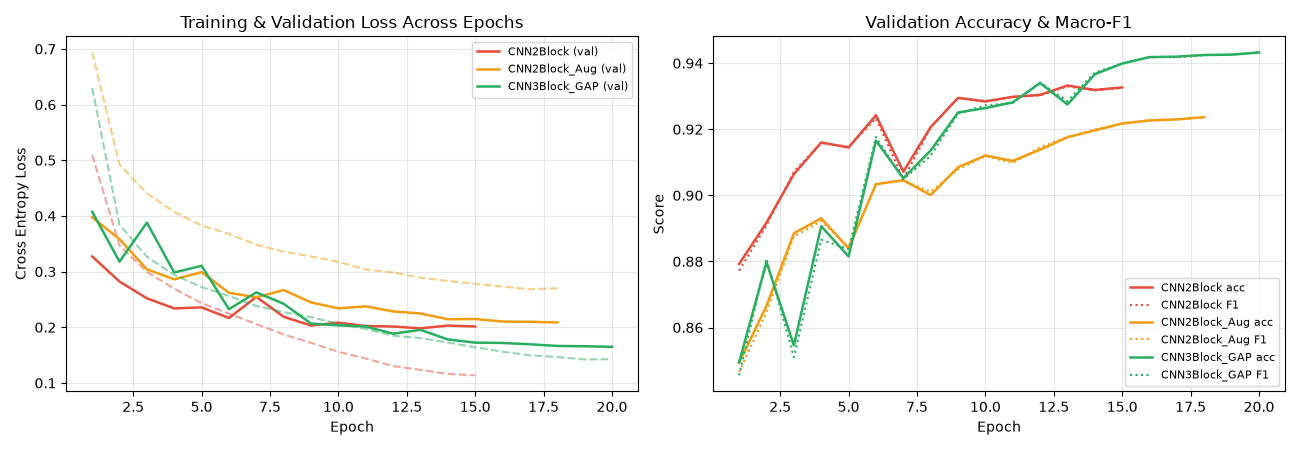

In [3]:
show('cnn_01_training_curves', 1000)

## 3. Did CNN Break the Upper-Body Garment Bottleneck?

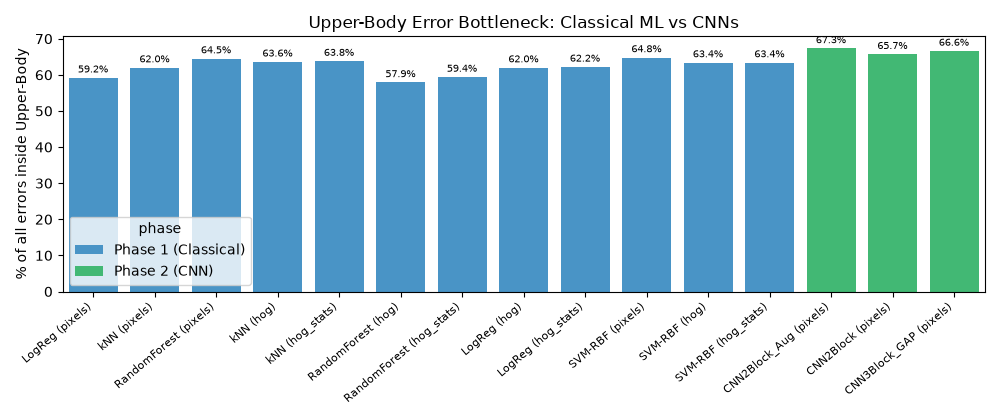

,model_display,phase,errors,upper_body_errors,share_pct,accuracy
0,LogReg (pixels),Phase 1 (Classical),1544,914,59.2,0.8456
1,kNN (pixels),Phase 1 (Classical),1439,892,62.0,0.8561
2,RandomForest (pixels),Phase 1 (Classical),1240,800,64.5,0.8760
3,kNN (hog),Phase 1 (Classical),1226,780,63.6,0.8774
4,kNN (hog_stats),Phase 1 (Classical),1224,781,63.8,0.8776
5,RandomForest (hog),Phase 1 (Classical),1219,706,57.9,0.8781
6,RandomForest (hog_stats),Phase 1 (Classical),1179,700,59.4,0.8821
7,LogReg (hog),Phase 1 (Classical),1148,712,62.0,0.8852
8,LogReg (hog_stats),Phase 1 (Classical),1106,688,62.2,0.8894
9,SVM-RBF (pixels),Phase 1 (Classical),1012,656,64.8,0.8988


In [4]:
show('res_10_upper_body_error_share_with_cnn', 850); pd.read_csv(TABLE_DIR/'upper_body_error_share_with_cnn.csv')

## 4. Per-Class Recall: Comparing All Models

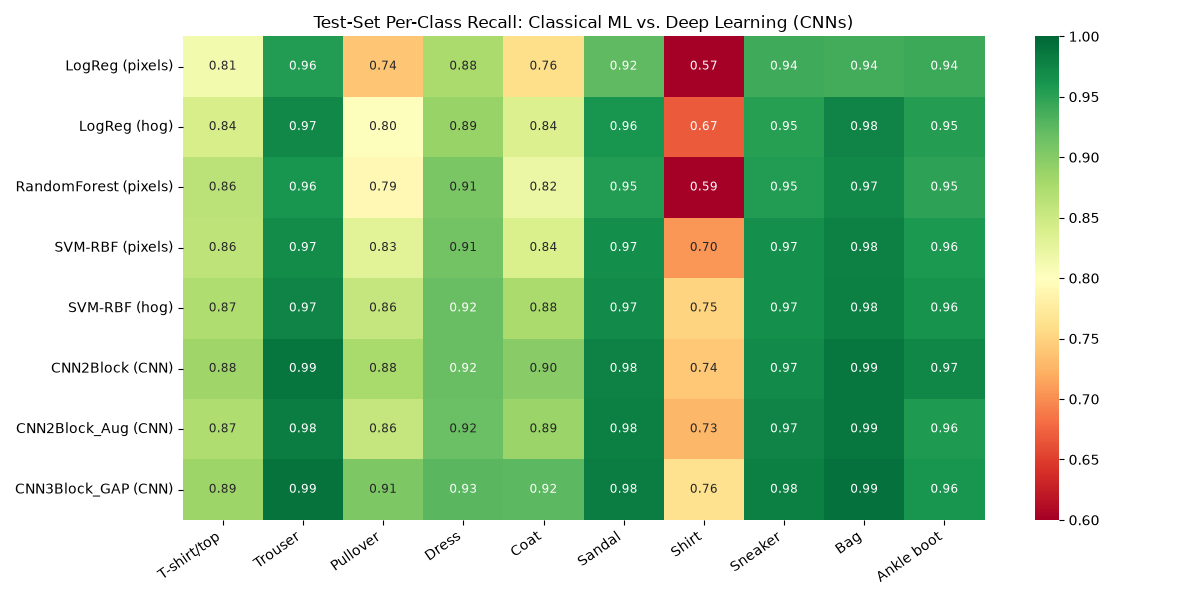

,Unnamed: 0,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,LogReg (pixels),0.813,0.956,0.739,0.875,0.760,0.923,0.569,0.940,0.939,0.942
1,LogReg (hog),0.842,0.972,0.802,0.889,0.836,0.961,0.668,0.952,0.976,0.954
2,RandomForest (pixels),0.863,0.961,0.791,0.907,0.819,0.955,0.587,0.955,0.973,0.949
3,SVM-RBF (pixels),0.862,0.970,0.830,0.911,0.838,0.968,0.705,0.966,0.979,0.959
4,SVM-RBF (hog),0.873,0.975,0.856,0.918,0.875,0.971,0.750,0.967,0.981,0.964
5,CNN2Block (CNN),0.884,0.989,0.877,0.918,0.898,0.977,0.742,0.971,0.986,0.974
6,CNN2Block_Aug (CNN),0.873,0.982,0.856,0.917,0.887,0.980,0.728,0.975,0.986,0.957
7,CNN3Block_GAP (CNN),0.885,0.990,0.906,0.926,0.924,0.982,0.763,0.980,0.992,0.961


In [5]:
show('res_09_per_class_recall_with_cnn', 1000); pd.read_csv(TABLE_DIR/'per_class_recall_phase2.csv')

## 5. Statistical Significance (McNemar: SVM vs CNN)

In [6]:
pd.read_csv(TABLE_DIR/'mcnemar_phase1_vs_phase2.csv')

,model_1,model_2,acc_model_1,acc_model_2,delta_acc,svm_only_correct,cnn_only_correct,chi2,p_value,significant_p001
0,SVM-RBF (HOG),CNN2Block,0.913,0.9216,0.0086,313,399,10.15,1.444993e-03,False
1,SVM-RBF (HOG),CNN2Block_Aug,0.913,0.9141,0.0011,352,363,0.14,7.084201e-01,False
2,SVM-RBF (HOG),CNN3Block_GAP,0.913,0.9309,0.0179,266,445,44.56,2.463540e-11,True


## 6. Interpretability: Grad-CAM Saliency Maps

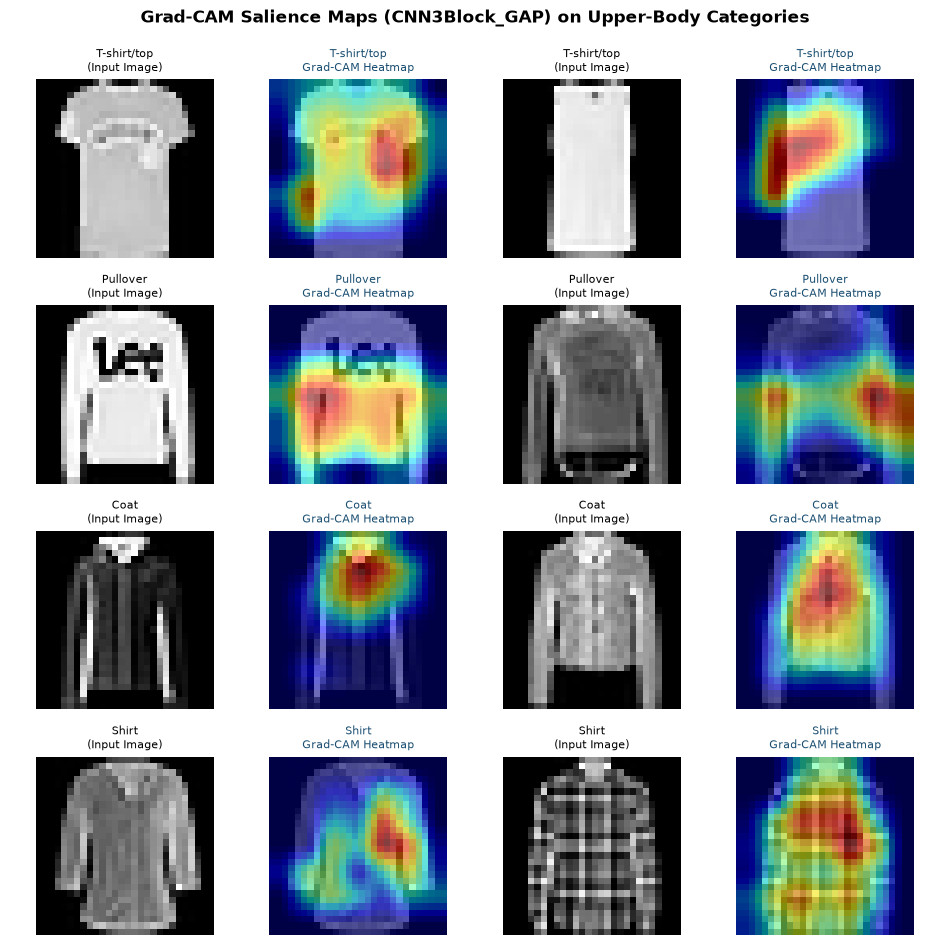

In [7]:
show('cnn_02_gradcam_gallery', 900)

## 7. Cost-Accuracy Frontier (Pareto Analysis)

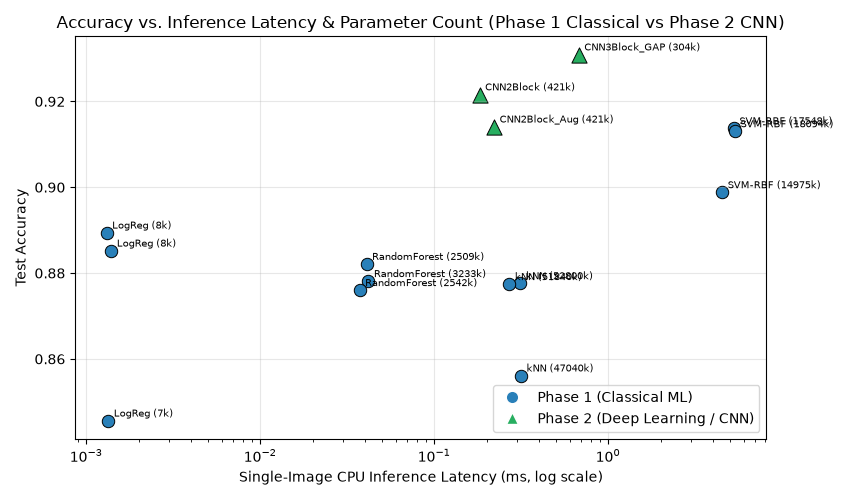

In [8]:
show('res_11_pareto_with_cnn', 750)